## Import Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Load Dataset

In [3]:
df = pd.read_csv("/content/WA_Fn-UseC_-HR-Employee-Attrition.csv")

In [4]:
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [5]:
df.shape

(1470, 35)

In [6]:
df.columns

Index(['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department',
       'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount',
       'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate',
       'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction',
       'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked',
       'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating',
       'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel',
       'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance',
       'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion',
       'YearsWithCurrManager'],
      dtype='object')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

In [8]:
df.isnull().sum()

,0
Age,0
Attrition,0
BusinessTravel,0
DailyRate,0
Department,0
DistanceFromHome,0
Education,0
EducationField,0
EmployeeCount,0
EmployeeNumber,0


In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.select_dtypes(include="object").nunique()

,0
Attrition,2
BusinessTravel,3
Department,3
EducationField,6
Gender,2
JobRole,9
MaritalStatus,3
Over18,1
OverTime,2


In [11]:
for col in df.select_dtypes(include="object").columns:
    print(f"\n{col}")
    print(df[col].value_counts())


Attrition
Attrition
No     1233
Yes     237
Name: count, dtype: int64

BusinessTravel
BusinessTravel
Travel_Rarely        1043
Travel_Frequently     277
Non-Travel            150
Name: count, dtype: int64

Department
Department
Research & Development    961
Sales                     446
Human Resources            63
Name: count, dtype: int64

EducationField
EducationField
Life Sciences       606
Medical             464
Marketing           159
Technical Degree    132
Other                82
Human Resources      27
Name: count, dtype: int64

Gender
Gender
Male      882
Female    588
Name: count, dtype: int64

JobRole
JobRole
Sales Executive              326
Research Scientist           292
Laboratory Technician        259
Manufacturing Director       145
Healthcare Representative    131
Manager                      102
Sales Representative          83
Research Director             80
Human Resources               52
Name: count, dtype: int64

MaritalStatus
MaritalStatus
Married     673


In [12]:
df_clean = df.copy()

In [13]:
df_clean[["EmployeeCount", "Over18", "StandardHours"]].nunique()

,0
EmployeeCount,1
Over18,1
StandardHours,1


In [14]:
df_clean.drop(
    columns=["EmployeeCount", "Over18", "StandardHours", "EmployeeNumber"],
    inplace=True
)

In [15]:
df_clean.shape

(1470, 31)

In [16]:
df_clean.dtypes

,0
Age,int64
Attrition,object
BusinessTravel,object
DailyRate,int64
Department,object
DistanceFromHome,int64
Education,int64
EducationField,object
EnvironmentSatisfaction,int64
Gender,object


In [17]:
categorical_cols = df_clean.select_dtypes(include="object").columns

for col in categorical_cols:
    print(f"\n--- {col} ---")
    print(df_clean[col].unique())


--- Attrition ---
['Yes' 'No']

--- BusinessTravel ---
['Travel_Rarely' 'Travel_Frequently' 'Non-Travel']

--- Department ---
['Sales' 'Research & Development' 'Human Resources']

--- EducationField ---
['Life Sciences' 'Other' 'Medical' 'Marketing' 'Technical Degree'
 'Human Resources']

--- Gender ---
['Female' 'Male']

--- JobRole ---
['Sales Executive' 'Research Scientist' 'Laboratory Technician'
 'Manufacturing Director' 'Healthcare Representative' 'Manager'
 'Sales Representative' 'Research Director' 'Human Resources']

--- MaritalStatus ---
['Single' 'Married' 'Divorced']

--- OverTime ---
['Yes' 'No']


# Attrition

In [18]:
df_clean["Attrition_Flag"] = df_clean["Attrition"].map({
    "Yes": 1,
    "No": 0
})

In [19]:
df_clean["Attrition_Flag"].value_counts()

,count
Attrition_Flag,
0,1233
1,237


In [20]:
attrition_rate = df_clean["Attrition_Flag"].mean() * 100

print(f"Attrition Rate: {attrition_rate:.2f}%")

Attrition Rate: 16.12%


## Experience Band

In [21]:
df_clean["Experience_Band"] = pd.cut(
    df_clean["TotalWorkingYears"],
    bins=[-1, 2, 5, 10, 20, np.inf],
    labels=["0-2 Years", "3-5 Years", "6-10 Years", "11-20 Years", "20+ Years"]
)

In [22]:
df_clean["Salary_Band"] = pd.cut(
    df_clean["MonthlyIncome"],
    bins=[-1, 3000, 6000, 10000, np.inf],
    labels=["Low", "Medium", "High", "Very High"]
)

In [23]:
print("Shape:", df_clean.shape)

print("\nMissing Values:")
print(df_clean.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df_clean.duplicated().sum())

Shape: (1470, 34)

Missing Values:
0

Duplicate Rows:
0


# EDA

## Employee Overview

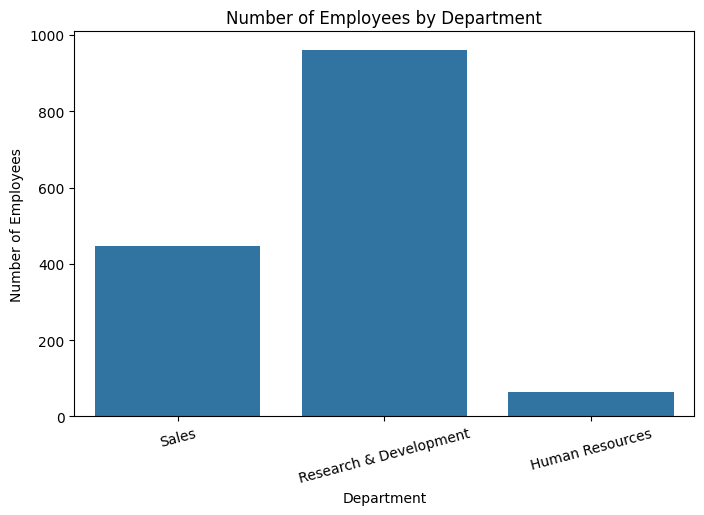

In [24]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df_clean, x="Department")

plt.title("Number of Employees by Department")
plt.xlabel("Department")
plt.ylabel("Number of Employees")

plt.xticks(rotation=15)
plt.show()

## Job Role

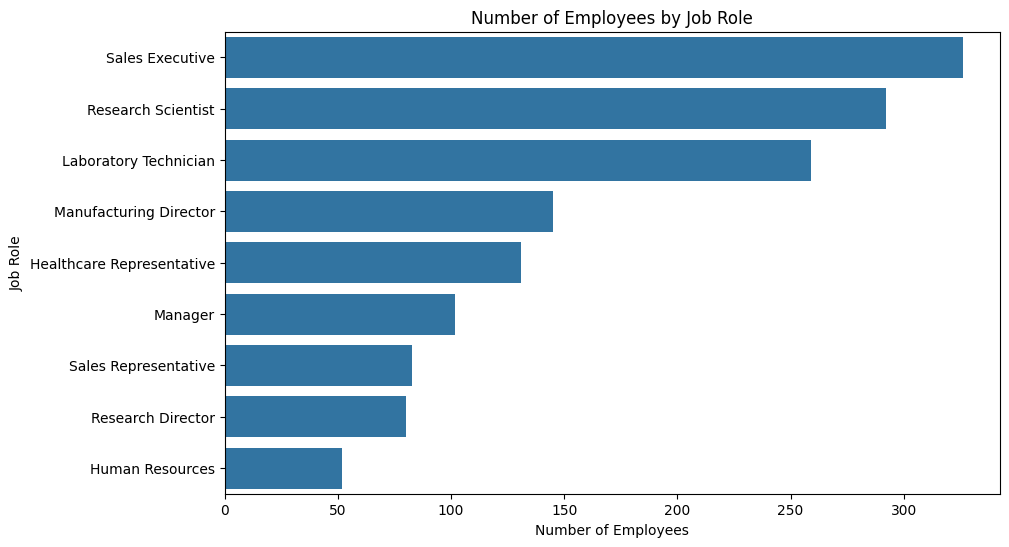

In [25]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df_clean,
    y="JobRole",
    order=df_clean["JobRole"].value_counts().index
)

plt.title("Number of Employees by Job Role")
plt.xlabel("Number of Employees")
plt.ylabel("Job Role")

plt.show()

Age distribution

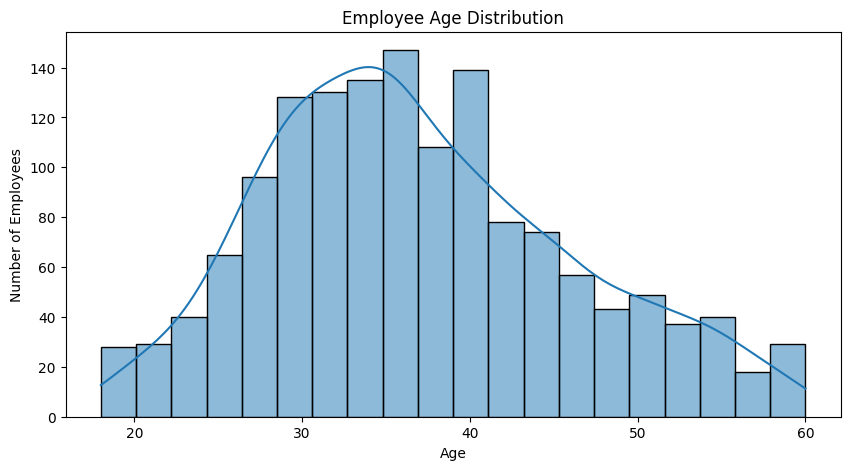

In [26]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_clean,
    x="Age",
    bins=20,
    kde=True
)

plt.title("Employee Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Employees")

plt.show()

## Age Groups

In [27]:
df_clean["Age_Group"] = pd.cut(
    df_clean["Age"],
    bins=[17, 24, 34, 44, 54, 60],
    labels=[
        "18-24",
        "25-34",
        "35-44",
        "45-54",
        "55-60"
    ]
)

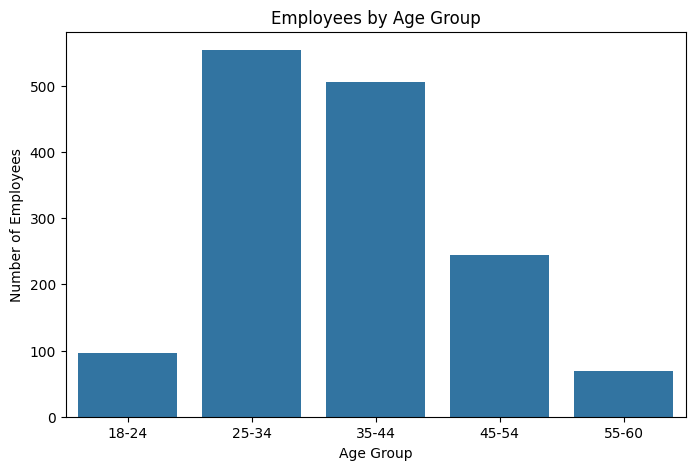

In [28]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x="Age_Group",
    order=["18-24", "25-34", "35-44", "45-54", "55-60"]
)

plt.title("Employees by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Employees")

plt.show()

In [30]:
df_clean["Gender"].value_counts()

,count
Gender,
Male,882
Female,588


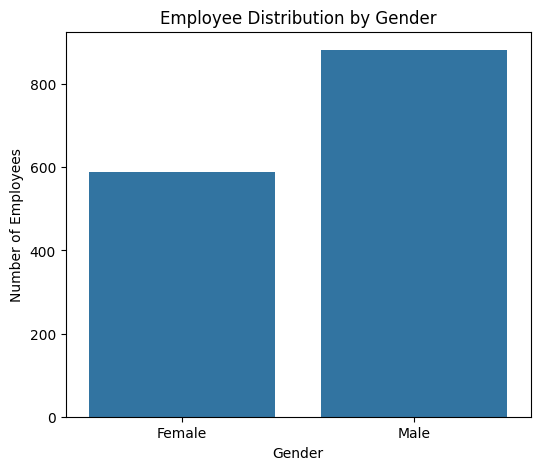

In [29]:
plt.figure(figsize=(6, 5))

sns.countplot(
    data=df_clean,
    x="Gender"
)

plt.title("Employee Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Employees")

plt.show()

## Attrition Rate

In [31]:
total_employees = len(df_clean)

print("Total Employees:", total_employees)

Total Employees: 1470


In [32]:
employees_left = (df_clean["Attrition"] == "Yes").sum()

print("Employees Left:", employees_left)

Employees Left: 237


In [33]:
attrition_rate = (
    (df_clean["Attrition"] == "Yes").sum()
    / len(df_clean)
) * 100

print(f"Attrition Rate: {attrition_rate:.2f}%")

Attrition Rate: 16.12%


### Attrition Distribution

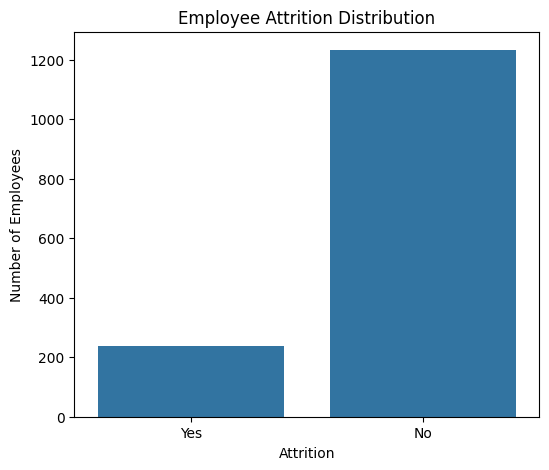

In [34]:
plt.figure(figsize=(6, 5))

sns.countplot(
    data=df_clean,
    x="Attrition"
)

plt.title("Employee Attrition Distribution")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")

plt.show()

Attrition by Department

In [35]:
attrition_by_department = (
    df_clean.groupby("Department")["Attrition_Flag"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print(attrition_by_department)

Department
Sales                     20.627803
Human Resources           19.047619
Research & Development    13.839750
Name: Attrition_Flag, dtype: float64


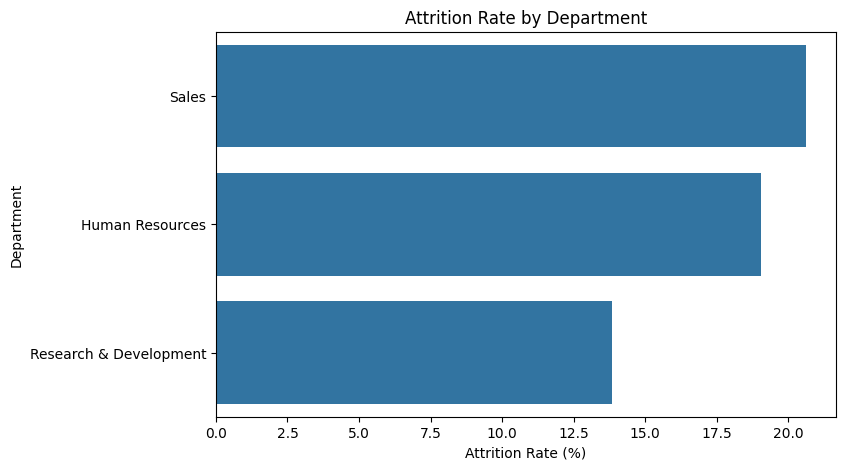

In [36]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=attrition_by_department.values,
    y=attrition_by_department.index
)

plt.title("Attrition Rate by Department")
plt.xlabel("Attrition Rate (%)")
plt.ylabel("Department")

plt.show()

Attrition by Job Role

In [37]:
attrition_by_role = (
    df_clean.groupby("JobRole")["Attrition_Flag"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print(attrition_by_role)

JobRole
Sales Representative         39.759036
Laboratory Technician        23.938224
Human Resources              23.076923
Sales Executive              17.484663
Research Scientist           16.095890
Manufacturing Director        6.896552
Healthcare Representative     6.870229
Manager                       4.901961
Research Director             2.500000
Name: Attrition_Flag, dtype: float64


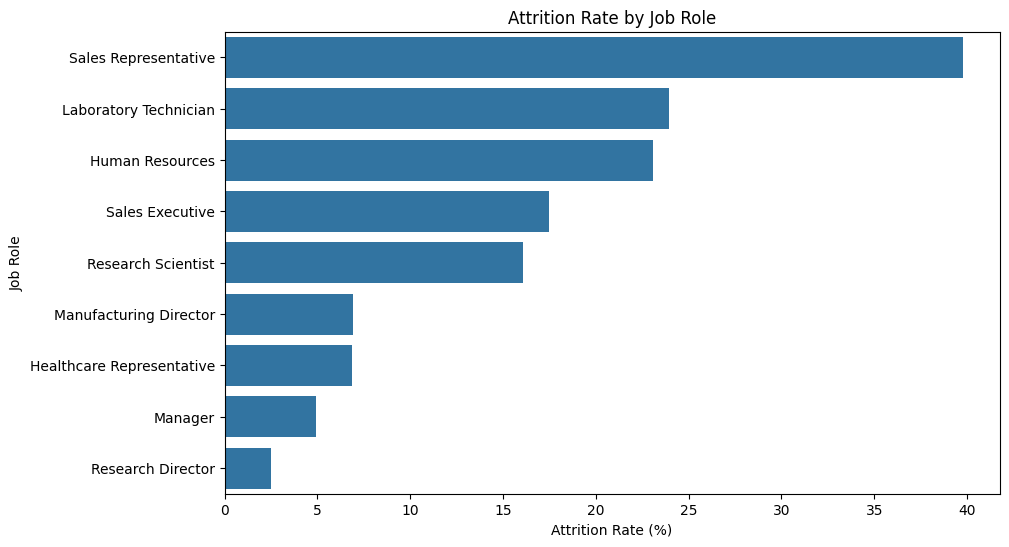

In [38]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=attrition_by_role.values,
    y=attrition_by_role.index
)

plt.title("Attrition Rate by Job Role")
plt.xlabel("Attrition Rate (%)")
plt.ylabel("Job Role")

plt.show()

Attrition vs OverTime

In [39]:
attrition_by_overtime = (
    df_clean.groupby("OverTime")["Attrition_Flag"]
    .mean()
    .mul(100)
)

print(attrition_by_overtime)

OverTime
No     10.436433
Yes    30.528846
Name: Attrition_Flag, dtype: float64


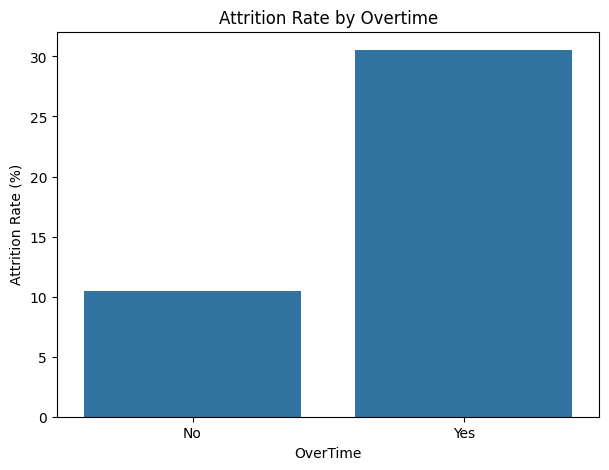

In [40]:
plt.figure(figsize=(7, 5))

sns.barplot(
    x=attrition_by_overtime.index,
    y=attrition_by_overtime.values
)

plt.title("Attrition Rate by Overtime")
plt.xlabel("OverTime")
plt.ylabel("Attrition Rate (%)")

plt.show()

Attrition vs Job Satisfaction

In [41]:
attrition_by_satisfaction = (
    df_clean.groupby("JobSatisfaction")["Attrition_Flag"]
    .mean()
    .mul(100)
)

print(attrition_by_satisfaction)

JobSatisfaction
1    22.837370
2    16.428571
3    16.515837
4    11.328976
Name: Attrition_Flag, dtype: float64


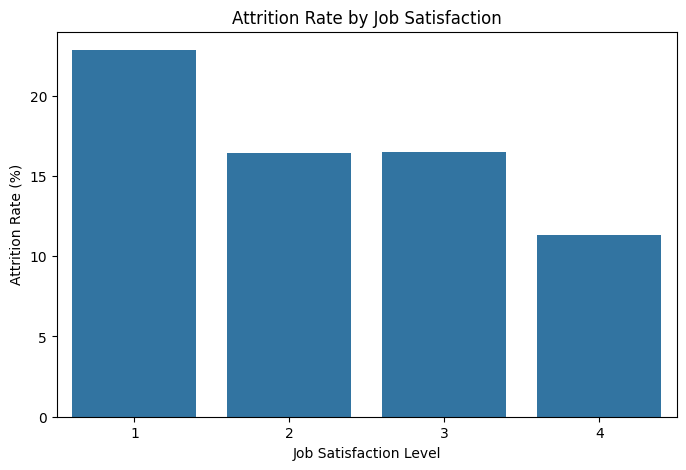

In [42]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=attrition_by_satisfaction.index,
    y=attrition_by_satisfaction.values
)

plt.title("Attrition Rate by Job Satisfaction")
plt.xlabel("Job Satisfaction Level")
plt.ylabel("Attrition Rate (%)")

plt.show()

Attrition vs Work-Life Balance

In [43]:
attrition_by_wlb = (
    df_clean.groupby("WorkLifeBalance")["Attrition_Flag"]
    .mean()
    .mul(100)
)

print(attrition_by_wlb)

WorkLifeBalance
1    31.250000
2    16.860465
3    14.221725
4    17.647059
Name: Attrition_Flag, dtype: float64


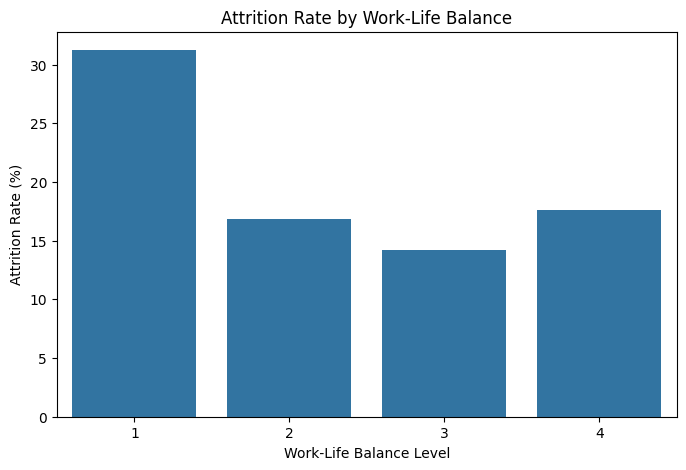

In [44]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=attrition_by_wlb.index,
    y=attrition_by_wlb.values
)

plt.title("Attrition Rate by Work-Life Balance")
plt.xlabel("Work-Life Balance Level")
plt.ylabel("Attrition Rate (%)")

plt.show()

## Salary & Experience Analysis

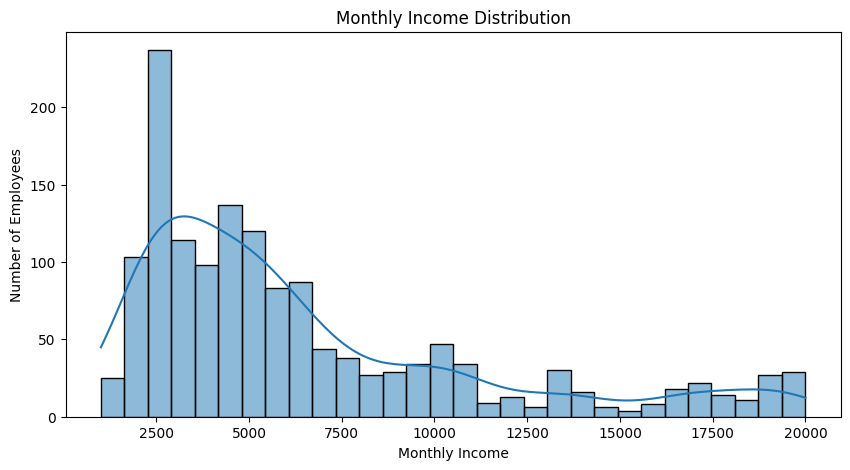

In [45]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_clean,
    x="MonthlyIncome",
    bins=30,
    kde=True
)

plt.title("Monthly Income Distribution")
plt.xlabel("Monthly Income")
plt.ylabel("Number of Employees")

plt.show()

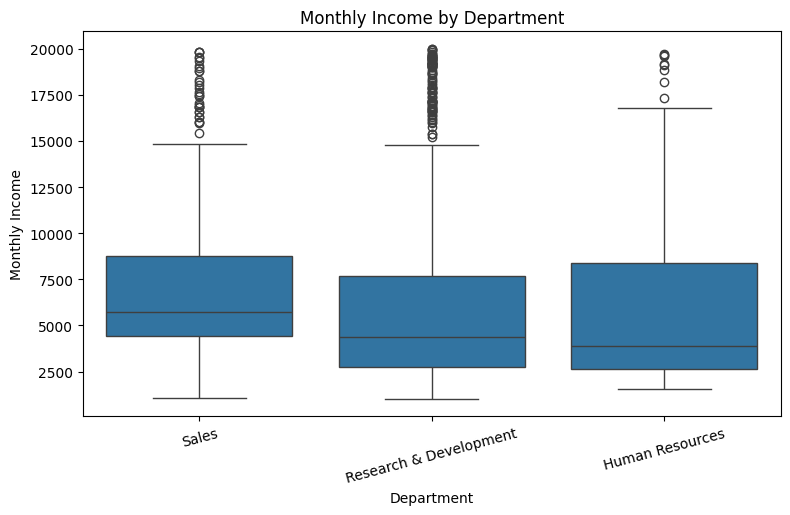

In [46]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df_clean,
    x="Department",
    y="MonthlyIncome"
)

plt.title("Monthly Income by Department")
plt.xlabel("Department")
plt.ylabel("Monthly Income")

plt.xticks(rotation=15)
plt.show()

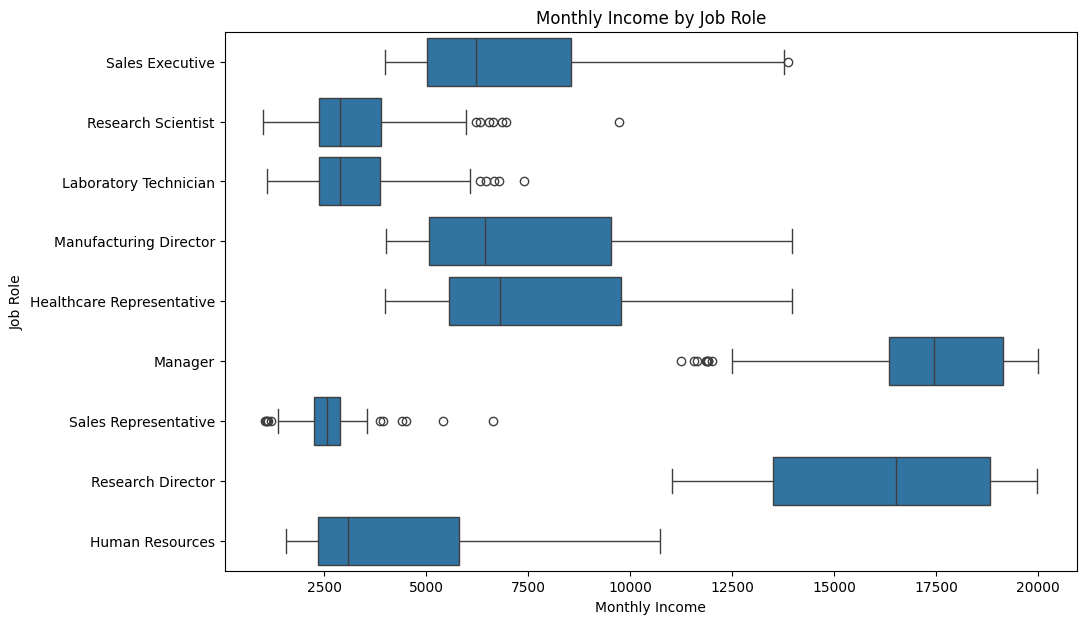

In [47]:
plt.figure(figsize=(11, 7))

sns.boxplot(
    data=df_clean,
    x="MonthlyIncome",
    y="JobRole"
)

plt.title("Monthly Income by Job Role")
plt.xlabel("Monthly Income")
plt.ylabel("Job Role")

plt.show()

In [48]:
salary_by_attrition = df_clean.groupby("Attrition")["MonthlyIncome"].mean()

print(salary_by_attrition)

Attrition
No     6832.739659
Yes    4787.092827
Name: MonthlyIncome, dtype: float64


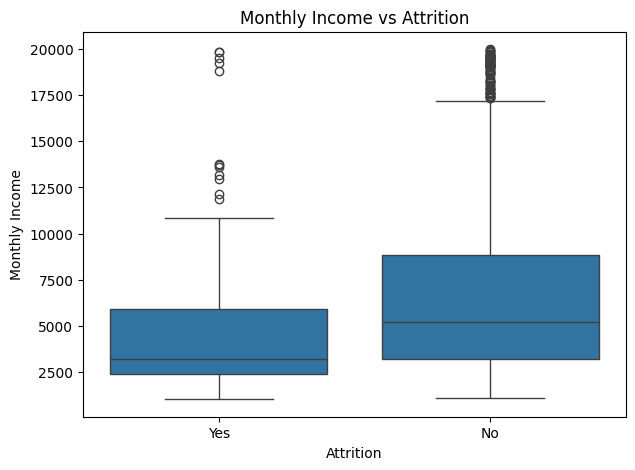

In [49]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df_clean,
    x="Attrition",
    y="MonthlyIncome"
)

plt.title("Monthly Income vs Attrition")
plt.xlabel("Attrition")
plt.ylabel("Monthly Income")

plt.show()

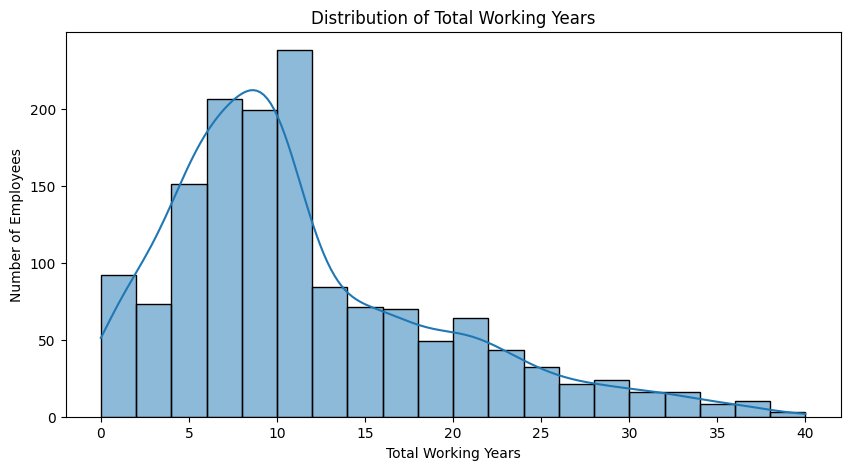

In [50]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_clean,
    x="TotalWorkingYears",
    bins=20,
    kde=True
)

plt.title("Distribution of Total Working Years")
plt.xlabel("Total Working Years")
plt.ylabel("Number of Employees")

plt.show()

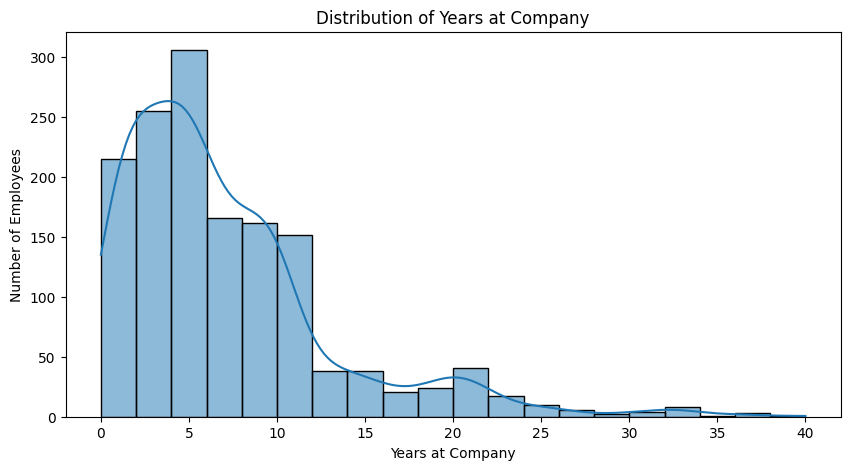

In [51]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_clean,
    x="YearsAtCompany",
    bins=20,
    kde=True
)

plt.title("Distribution of Years at Company")
plt.xlabel("Years at Company")
plt.ylabel("Number of Employees")

plt.show()

In [52]:
attrition_by_experience = (
    df_clean.groupby("Experience_Band", observed=False)["Attrition_Flag"]
    .mean()
    .mul(100)
)

print(attrition_by_experience)

Experience_Band
0-2 Years      43.902439
3-5 Years      19.170984
6-10 Years     14.991763
11-20 Years    11.470588
20+ Years       7.729469
Name: Attrition_Flag, dtype: float64


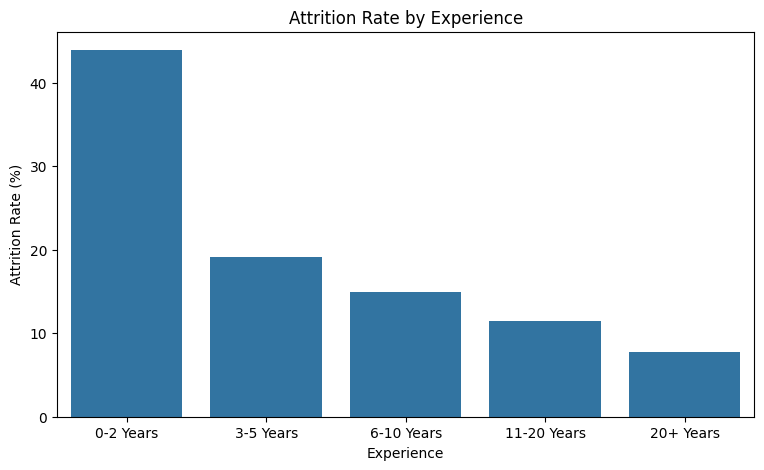

In [53]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=attrition_by_experience.index,
    y=attrition_by_experience.values
)

plt.title("Attrition Rate by Experience")
plt.xlabel("Experience")
plt.ylabel("Attrition Rate (%)")

plt.show()

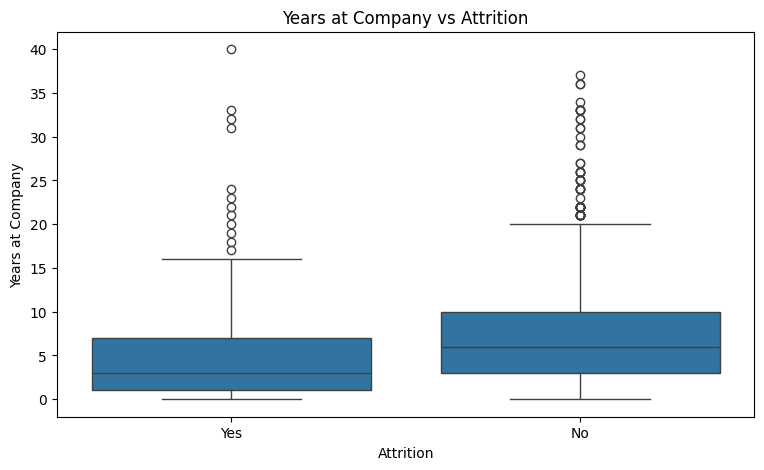

In [54]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df_clean,
    x="Attrition",
    y="YearsAtCompany"
)

plt.title("Years at Company vs Attrition")
plt.xlabel("Attrition")
plt.ylabel("Years at Company")

plt.show()

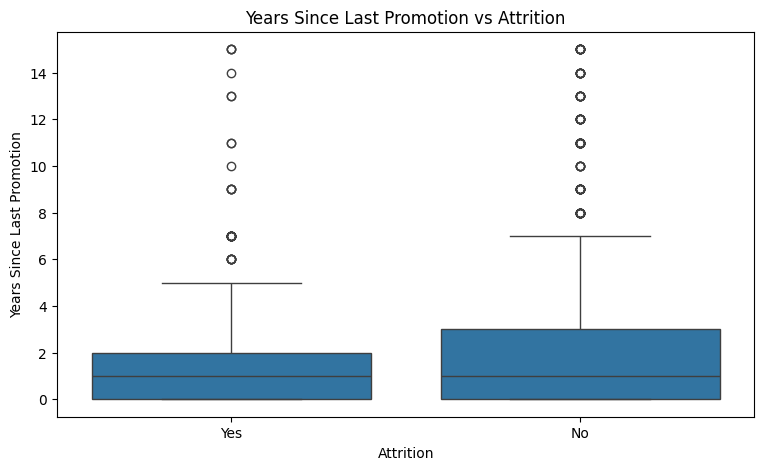

In [55]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df_clean,
    x="Attrition",
    y="YearsSinceLastPromotion"
)

plt.title("Years Since Last Promotion vs Attrition")
plt.xlabel("Attrition")
plt.ylabel("Years Since Last Promotion")

plt.show()

## Performance & Satisfaction

In [56]:
performance_counts = df_clean["PerformanceRating"].value_counts().sort_index()

print(performance_counts)

PerformanceRating
3    1244
4     226
Name: count, dtype: int64


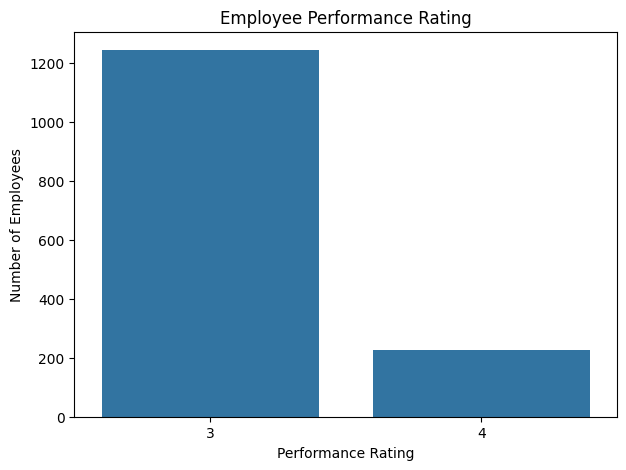

In [57]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_clean,
    x="PerformanceRating"
)

plt.title("Employee Performance Rating")
plt.xlabel("Performance Rating")
plt.ylabel("Number of Employees")

plt.show()

In [58]:
attrition_by_performance = (
    df_clean.groupby("PerformanceRating")["Attrition_Flag"]
    .mean()
    .mul(100)
)

print(attrition_by_performance)

PerformanceRating
3    16.077170
4    16.371681
Name: Attrition_Flag, dtype: float64


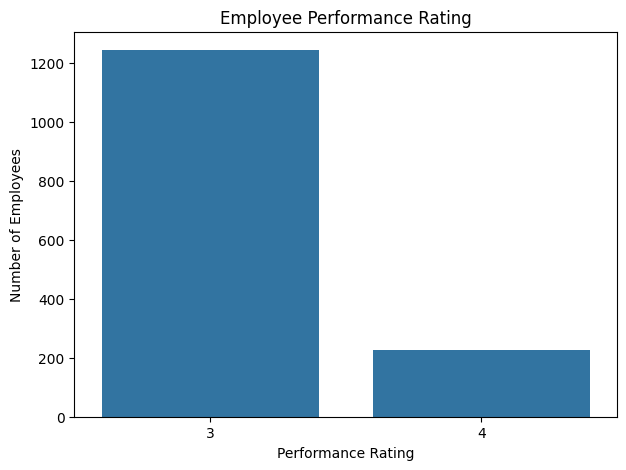

In [59]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_clean,
    x="PerformanceRating"
)

plt.title("Employee Performance Rating")
plt.xlabel("Performance Rating")
plt.ylabel("Number of Employees")

plt.show()

Satisfaction Analysis

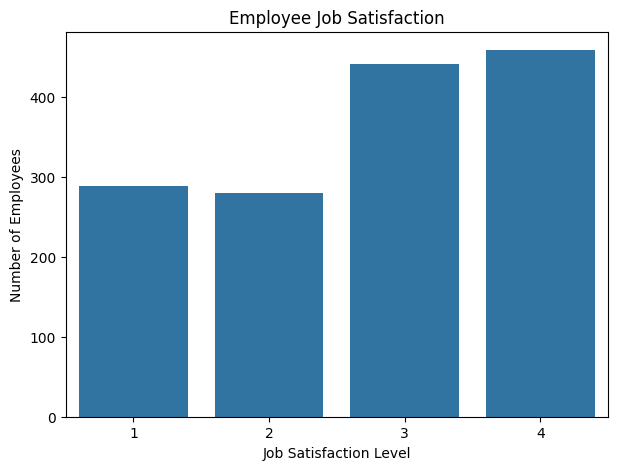

In [60]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_clean,
    x="JobSatisfaction"
)

plt.title("Employee Job Satisfaction")
plt.xlabel("Job Satisfaction Level")
plt.ylabel("Number of Employees")

plt.show()

In [61]:
satisfaction_map = {
    1: "Low",
    2: "Medium",
    3: "High",
    4: "Very High"
}

df_clean["JobSatisfaction_Level"] = (
    df_clean["JobSatisfaction"].map(satisfaction_map)
)

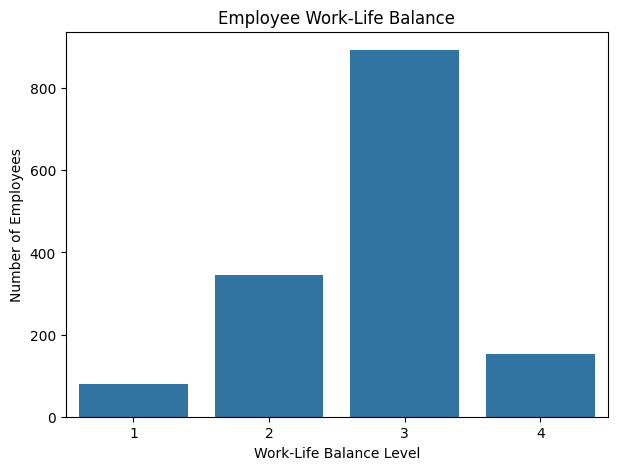

In [62]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_clean,
    x="WorkLifeBalance"
)

plt.title("Employee Work-Life Balance")
plt.xlabel("Work-Life Balance Level")
plt.ylabel("Number of Employees")

plt.show()

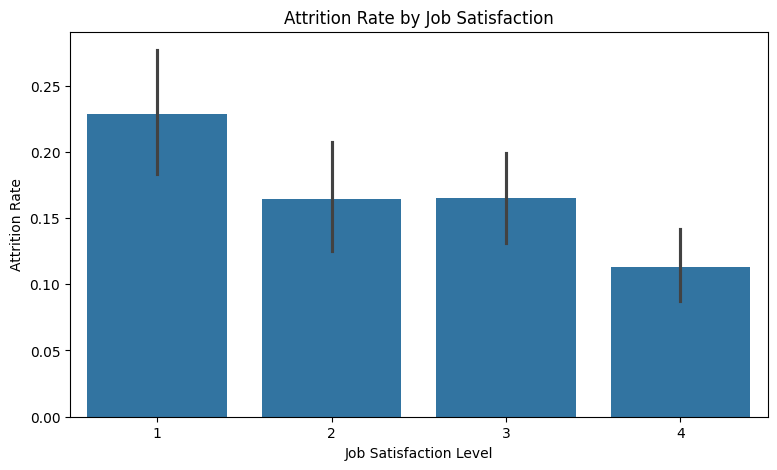

In [63]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df_clean,
    x="JobSatisfaction",
    y="Attrition_Flag"
)

plt.title("Attrition Rate by Job Satisfaction")
plt.xlabel("Job Satisfaction Level")
plt.ylabel("Attrition Rate")

plt.show()

## Correlation Heatmap

In [64]:
selected_cols = [
    "Age",
    "MonthlyIncome",
    "TotalWorkingYears",
    "YearsAtCompany",
    "YearsInCurrentRole",
    "YearsSinceLastPromotion",
    "YearsWithCurrManager",
    "JobSatisfaction",
    "WorkLifeBalance",
    "PerformanceRating",
    "Attrition_Flag"
]

correlation = df_clean[selected_cols].corr()

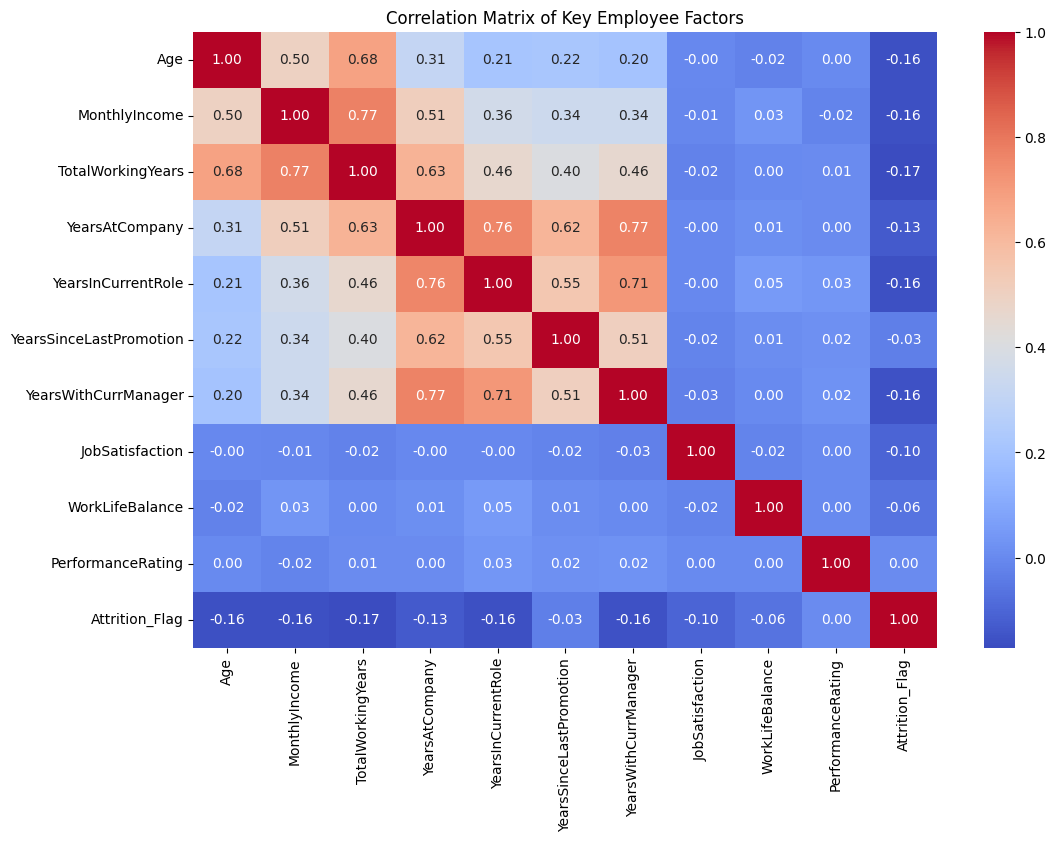

In [65]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Matrix of Key Employee Factors")

plt.show()